This example shows how scikit-learn can be used to recognize images of hand-written digits, from 0-9.

In [1]:
import matplotlib.pyplot as plt
from sklearn import datasets, metrics, svm
from sklearn.model_selection import train_test_split

<h2>Digits dataset</h2>

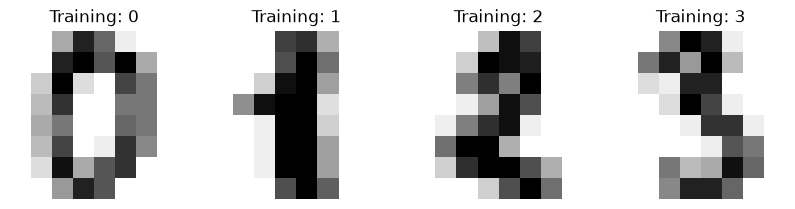

In [5]:
digits = datasets.load_digits()

_,axes = plt.subplots(nrows=1, ncols=4, figsize=(10,3))
for ax, image, label in zip(axes, digits.images, digits.target):
    ax.set_axis_off()
    ax.imshow(image, cmap=plt.cm.gray_r, interpolation="nearest")
    ax.set_title("Training: %i" % label)


<h2>Classification</h2>
To apply a classifier on this data, we need to flatten the images, turning each 2-D array of grayscale values from shape (8, 8) into shape (64,)

In [7]:
#flatten the images
n_samples = len(digits.images)
data = digits.images.reshape((n_samples, -1))

#Create a Support Vector Classifier
clf = svm.SVC(gamma=0.0001)

# Split data into 50% train and 50% test subsets
X_train, X_test, y_train, y_test = train_test_split(
    data, digits.target, test_size=0.5, shuffle=False
)

# Learn the digits on the train subset
clf.fit(X_train, y_train)

# Predict the value of the digit on the test subset
predicted = clf.predict(X_test)

Below we visualize the first 4 test samples and show their predicted digit value in the title.

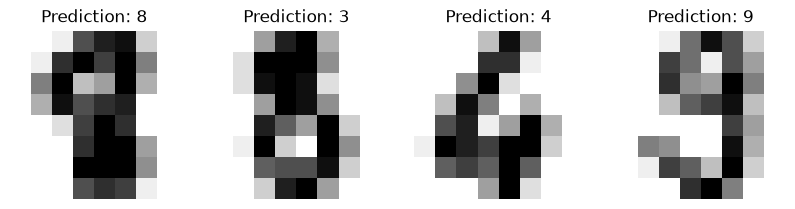

In [8]:
_, axes = plt.subplots(nrows=1, ncols=4, figsize=(10,3))
for ax, image, prediction in zip(axes, X_test, predicted):
    ax.set_axis_off()
    image = image.reshape(8,8)
    ax.imshow(image, cmap=plt.cm.gray_r, interpolation="nearest")
    ax.set_title(f"Prediction: {prediction}")

classification_report builds a text report showing the main classification metrics.

In [11]:
print(
    f"Classification report for classifier {clf}:\n"
    f"{metrics.classification_report(y_test, predicted)}\n"
)

Classification report for classifier SVC(gamma=0.0001):
              precision    recall  f1-score   support

           0       0.99      0.99      0.99        88
           1       0.95      0.90      0.93        91
           2       1.00      0.94      0.97        86
           3       0.95      0.87      0.91        91
           4       0.99      0.95      0.97        92
           5       0.90      0.96      0.93        91
           6       0.99      0.99      0.99        91
           7       0.92      0.98      0.95        89
           8       0.92      0.89      0.90        88
           9       0.83      0.95      0.88        92

    accuracy                           0.94       899
   macro avg       0.94      0.94      0.94       899
weighted avg       0.94      0.94      0.94       899


